# Gaia epoch photometry of ATLAS J1013−4516

MIT Gaia DR4 Warm Up Workshop · November 5–6, 2026

## From sparse light curves to a longer orbital clock

- **Gaia epoch photometry** is a time series of individual brightness measurements, with times, flux uncertainties and quality information, rather than a single catalogue mean magnitude. DR3 provides G, BP and RP field-of-view (FoV) measurements for a selected subset of sources. The scanning law gives irregular, sky-dependent sampling over 34 months: typically tens of visits, rather than continuous coverage. DR3 published about **11.75 million photometric time series**, including variables and the Gaia Andromeda Photometric Survey ([Gaia Collaboration 2023](https://doi.org/10.1051/0004-6361/202243940)).

- **Precision depends on brightness, band and sampling.** Catalogue mean-flux precision is not the uncertainty of an individual epoch. For this faint target (catalogue G ≈ 19.5), the stored series contains **54 measurements over 1,010 days**, with a **median reported flux uncertainty of 1.80%** (approximately 19.6 mmag). The next cell verifies these values. These are reported statistical errors; the timing-template residuals provide a separate check.

- **Exposure and timestamp convention:** an ungated CCD integrates for approximately **4.42 s**; a DR3 G-band FoV point usually combines about **nine CCD measurements over a ∼44 s interval**. Native epoch times are **BJD_TCB − 2455197.5 days**, already corrected to the Solar-system barycentre. Converting to BJD_TDB changes the time scale; it does not require a second barycentric light-travel correction. See the documented conversion and J1013 caveat below ([Gaia epoch data model](https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_photometry/ssec_dm_epoch_photometry.html); [CCD integration and gates](https://doi.org/10.1051/0004-6361/202039448)).

- **Beyond white dwarfs:** Gaia multiband light curves enabled all-sky characterisation of **140,784 RR Lyrae and 9,575 Cepheids** ([Clementini et al. 2019](https://doi.org/10.1051/0004-6361/201833374)), and transit searches discovered **Gaia-1b and Gaia-2b**, confirmed with radial velocities ([Panahi et al. 2022](https://doi.org/10.1051/0004-6361/202243497)). These are direct time-series applications, including the Gaia processing teams' analyses.

- **Science using the Andromeda survey:** GAPS supplies a comparison population unselected by variability. Mas et al. (2026) used GAPS alongside Gaia young-star light curves to develop variability metrics; they characterised about **23,000 young sources**, distinguishing behaviours linked to accretion, extinction and rotation ([paper](https://doi.org/10.1051/0004-6361/202554522)). This is foreground/young-star science using GAPS, not a measurement of M31's stellar population. Holl et al. (2023) also used GAPS to investigate scan-angle-dependent signals and false periods ([paper](https://doi.org/10.1051/0004-6361/202245353)).

- **Short-period precedent:** Steen et al. (2024) recovered periods independently from Gaia for 105 white dwarfs, including seven below 1,000 seconds ([paper](https://doi.org/10.3847/1538-4357/ad3e60)). Seasonal waveform measurements can also extend a binary's orbital clock, with O–C curvature constraining its period derivative.

- **What changes in DR4?** ESA's expected content includes a 66-month baseline, much broader light-curve availability, and both FoV photometry and **individual-CCD G-band photometry** (`epoch_photometry_ccd`). CCD measurements offer sampling within a transit, helping resolve rapid waveform structure that FoV averages smear. They share calibration and transit-level systematics, so more samples do not automatically mean equally many independent timings. These are planned products, pending validation as of this workshop ([ESA DR4 content](https://www.cosmos.esa.int/web/gaia/dr4)).

- **What I will show:** the Gaia/ATLAS fold of the 8.56-minute binary J1013; three seasonal Gaia timings measured directly from its stored fluxes; and the O–C and conditional $\dot P$ uncertainty **before and after** adding those timings to 12 non-Gaia epochs. No previously supplied Gaia timing epochs enter this notebook. The scientific opportunity is an earlier orbital clock; DR4 should make this approach available for many more targets and improve our view of rapid light-curve structure.

- The published result is $\dot P=(-1.60\pm0.07)\times10^{-12}$ s/s ([Chickles et al. 2026](https://doi.org/10.3847/1538-4357/ae4871)). This notebook's new Gaia timings are exploratory, with template and time-scale limitations described below; the before/after fit is a fresh calculation, not a reproduction of the published measurement.

Run All writes figures and numeric products to `figures/` and `tables/`.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation
from astropy.utils import iers
import astropy.units as u

# Run from this directory, or from its parent.
ROOT = Path.cwd()
if not (ROOT / 'data/source_manifest.json').exists():
    ROOT = ROOT / 'j1013_gaia_notebook'
if not (ROOT / 'data/source_manifest.json').exists():
    raise FileNotFoundError('Open the notebook with its bundled data/ directory beside it.')
DATA = ROOT / 'data'
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
TABLE = ROOT / 'tables'; TABLE.mkdir(exist_ok=True)
iers.conf.auto_download = False
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'savefig.dpi':220, 'figure.dpi':110})
COLORS = {'Gaia':'#202020','ATLAS-c':'#0072B2','ATLAS-o':'#E69F00',
          'ATLAS':'#E69F00','ULTRACAM':'#009E73','Proto-Lightspeed':'#CC79A7'}
T0_PUBLISHED = 60033.2044878
P_PUBLISHED_S = 513.593303
PDOT_PUBLISHED = -1.60e-12
N_PHASE_BINS = 50

def save_figure(fig, stem):
    for extension in ('pdf','png'):
        fig.savefig(FIG / f'{stem}.{extension}', bbox_inches='tight')

manifest = json.loads((DATA/'source_manifest.json').read_text())
for item in manifest:
    assert hashlib.sha256((ROOT/item['file']).read_bytes()).hexdigest() == item['sha256']
print(f'Verified checksums of {len(manifest)} source input files.')

intro_gaia = np.loadtxt(DATA/'gaia.dat')
relative_error = intro_gaia[:,3]/np.abs(intro_gaia[:,2])
print(f'J1013: {len(intro_gaia)} stored Gaia measurements over {np.ptp(intro_gaia[:,0]):.1f} days.')
print(f'Median reported flux error: {100*np.median(relative_error):.2f}% '
      f'(small-error magnitude equivalent {1000*2.5/np.log(10)*np.median(relative_error):.1f} mmag).')
print('Reported point errors, not empirical repeatability or eclipse-timing precision.')


Verified checksums of 18 source input files.
J1013: 54 stored Gaia measurements over 1010.0 days.
Median reported flux error: 1.80% (small-error magnitude equivalent 19.6 mmag).
Reported point errors, not empirical repeatability or eclipse-timing precision.


## Where are the published Gaia DR3 light curves?

- **11,754,237 sources** have published epoch photometry. This map counts all of them, using `has_epoch_photometry = true`, with no magnitude cut or random subsampling.
- The bright patch around **M31** includes the **1,257,319-source Gaia Andromeda Photometric Survey (GAPS)**, which publishes light curves regardless of variability. Its 5.5° selection region includes foreground Milky Way sources; the patch is not a map of M31 membership ([Evans et al. 2023](https://doi.org/10.1051/0004-6361/202244204)).
- Colour shows sources per square degree in equal-area, nested HEALPix cells (order 6; 0.839 deg² each). The all-sky map is in Galactic coordinates. The right panel is the original image of **Evans et al. (2023), Figure 1**, showing the GAPS field in equatorial coordinates; its density colours use the paper’s own logarithmic scale. The colour bar beneath the left panel applies only to our all-sky map. The cached archive counts, exact ADQL query and retrieval metadata are included in `data/`, so Run All works offline.

*Right panel: Evans et al. (2023), A&A 674, A4, Figure 1, [DOI: 10.1051/0004-6361/202244204](https://doi.org/10.1051/0004-6361/202244204). Original figure image retained unchanged; retrieved from the paper’s arXiv version. This is a source-distribution diagram, not a direct image of M31.*


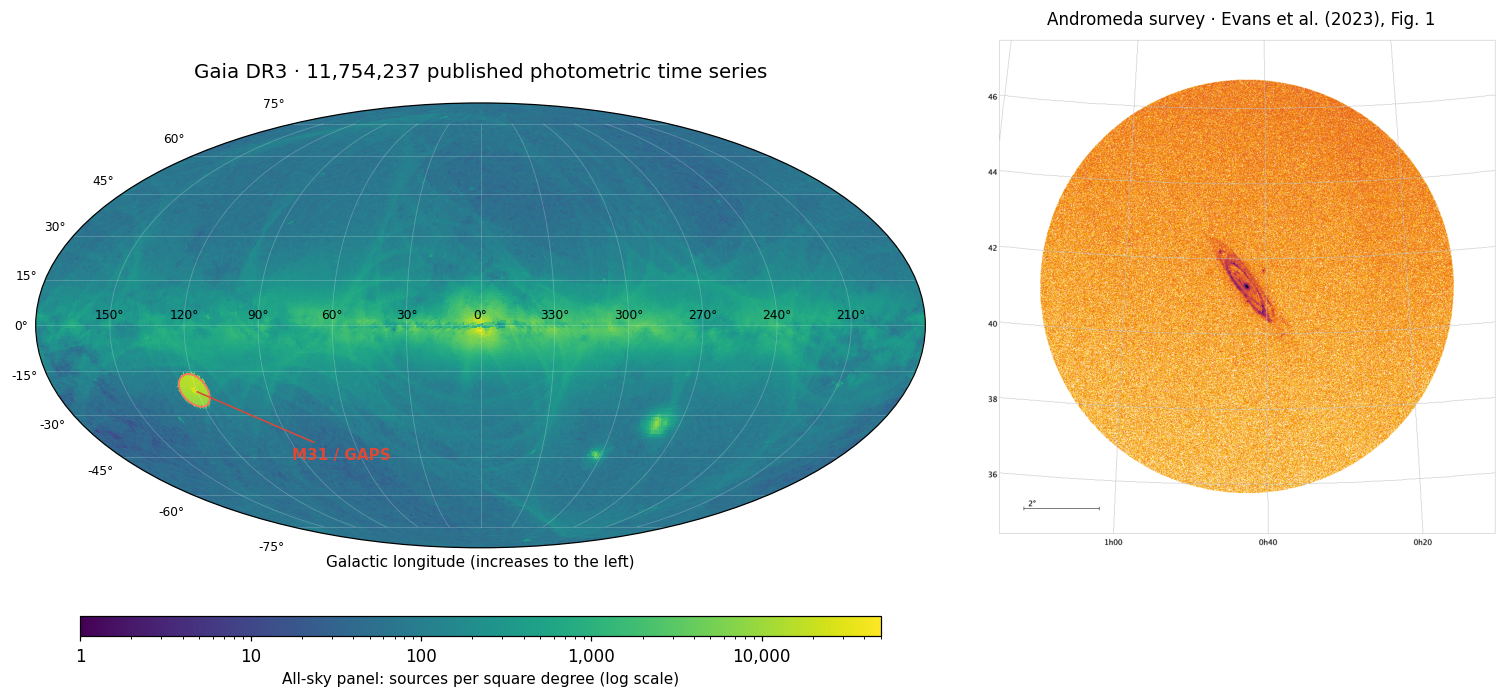

Full sample: 11,754,237 sources; GAPS: 1,257,319.


In [2]:
from astropy_healpix import HEALPix
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogLocator

sky_counts = pd.read_csv(DATA/'gaia_dr3_epoch_photometry_healpix6.csv')
sky_meta = json.loads((DATA/'gaia_dr3_epoch_photometry_sky_metadata.json').read_text())
assert sky_counts.n_sources.sum() == sky_meta['n_sources'] == 11754237
is_gaps = sky_counts.in_andromeda_survey.astype(str).str.lower().eq('true')
assert sky_counts.loc[is_gaps,'n_sources'].sum() == 1257319
hp = HEALPix(nside=64,order='nested',frame='icrs')
area_deg2 = hp.pixel_area.to_value(u.deg**2)
counts = np.zeros(hp.npix,dtype='int64')
np.add.at(counts,sky_counts.healpix6.to_numpy(),sky_counts.n_sources.to_numpy())
density = counts/area_deg2

# Rasterize the equal-area HEALPix counts for display; no smoothing or interpolation.
lon_edges = np.linspace(-np.pi,np.pi,1441)
lat_edges = np.linspace(-np.pi/2,np.pi/2,721)
lon_centres = (lon_edges[:-1]+lon_edges[1:])/2
lat_centres = (lat_edges[:-1]+lat_edges[1:])/2
xx,yy = np.meshgrid(lon_centres,lat_centres)
positions = SkyCoord(l=-xx*u.rad,b=yy*u.rad,frame='galactic').icrs
image_density = density[hp.skycoord_to_healpix(positions)]

fig = plt.figure(figsize=(14,6.2),layout='constrained')
gs = fig.add_gridspec(1,2,width_ratios=[1.85,1.25])
ax = fig.add_subplot(gs[0],projection='mollweide')
norm = LogNorm(vmin=1,vmax=50000)
cmap = plt.get_cmap('viridis').copy();cmap.set_bad('#eeeeee')
artist = ax.pcolormesh(lon_edges,lat_edges,np.ma.masked_equal(image_density,0),
                       norm=norm,cmap=cmap,shading='flat',rasterized=True)
ax.grid(color='white',alpha=.25,lw=.5)
ticks = np.arange(-150,151,30)
ax.set_xticks(np.deg2rad(ticks))
ax.set_xticklabels([f'{(-v)%360}°' for v in ticks],fontsize=8)
ax.tick_params(axis='y',labelsize=8)
ax.set_xlabel('Galactic longitude (increases to the left)',fontsize=10)
ax.set_title('Gaia DR3 · 11,754,237 published photometric time series',fontsize=13,pad=17)

m31 = SkyCoord(ra=10.6847083*u.deg,dec=41.26875*u.deg,frame='icrs')
boundary = m31.directional_offset_by(np.linspace(0,360,361)*u.deg,5.5*u.deg)
gal = boundary.galactic
bx = -gal.l.wrap_at(180*u.deg).rad;by = gal.b.rad
ax.plot(bx,by,color='#ff745e',lw=1.2)
mx = -m31.galactic.l.wrap_at(180*u.deg).rad;my = m31.galactic.b.rad
ax.annotate('M31 / GAPS',xy=(mx,my),xytext=(mx+.45,my-.42),color='#dd4936',
            fontsize=10,fontweight='bold',arrowprops=dict(arrowstyle='-',color='#dd4936'))

zoom = fig.add_subplot(gs[1])
# Evans et al. Figure 1, displayed without alteration.
zoom.imshow(plt.imread(FIG/'literature/evans2023_gaps_fig1.png'))
zoom.set_axis_off()
zoom.set_title('Andromeda survey · Evans et al. (2023), Fig. 1',fontsize=11,pad=10)
# The all-sky density calibration does not apply to the literature panel.
cb = fig.colorbar(artist,ax=ax,location='bottom',shrink=.9,pad=.08,aspect=40)
cb.set_label('All-sky panel: sources per square degree (log scale)',fontsize=10)
cb.set_ticks([1,10,100,1000,10000]);cb.set_ticklabels(['1','10','100','1,000','10,000'])
save_figure(fig,'gaia_dr3_epoch_photometry_sky')
plt.show()
print(f'Full sample: {counts.sum():,} sources; GAPS: {sky_counts.loc[is_gaps,"n_sources"].sum():,}.')


## Sampling and brightness of the published sample

- These are **full-sample archive histograms**, split into GAPS and the rest of the sky. Each panel accounts for all 11,754,237 sources, including any missing summary values reported beneath it.
- “Number of epochs” here means the **FoV observations selected for variability analysis** (`num_selected_g_fov`, `num_selected_bp`, `num_selected_rp`). It is not the number of CCD exposures or necessarily the number of rows returned in an unfiltered download. Zero and missing values are kept distinct.
- The baseline is the duration of the selected G-band time series (25-day bins); brightness is `vari_summary.mean_mag_g_fov` (0.5-mag bins). The selection differs between the GAPS field and variability-selected sources elsewhere, so these distributions are not survey completeness curves. [Gaia summary-field definitions](https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_variability_tables/ssec_dm_vari_summary.html).


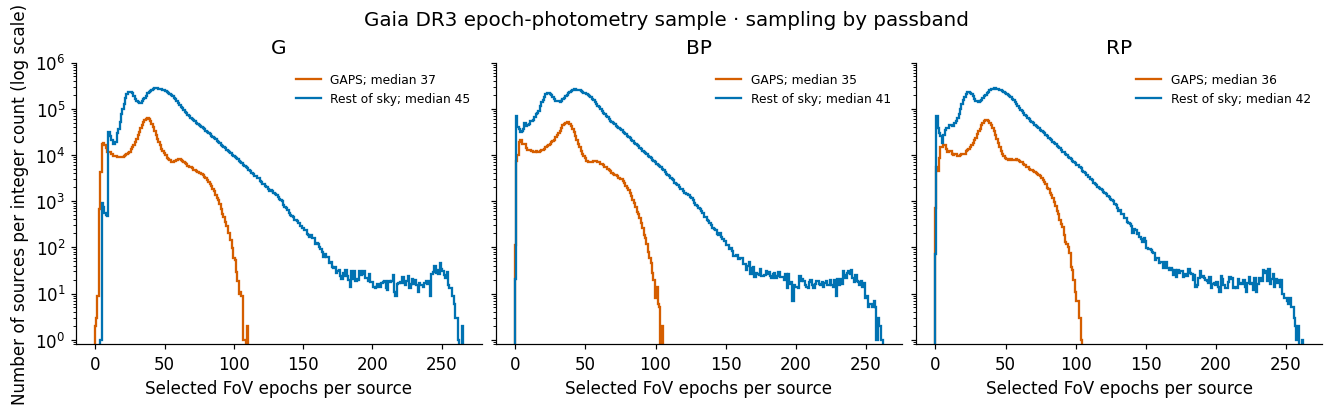

,band,population,n_sources,median_selected_epochs,missing_summary,zero_selected
0,g,GAPS,1257319,37.0,0,2
1,g,Rest of sky,10496918,45.0,0,0
2,bp,GAPS,1257319,35.0,14835,111
3,bp,Rest of sky,10496918,41.0,5953,21
4,rp,GAPS,1257319,36.0,13763,723
5,rp,Rest of sky,10496918,42.0,5801,72


baseline_g, GAPS: missing = 3; total = 1,257,319
baseline_g, Rest of sky: missing = 0; total = 10,496,918
magnitude_g, GAPS: missing = 0; total = 1,257,319
magnitude_g, Rest of sky: missing = 0; total = 10,496,918


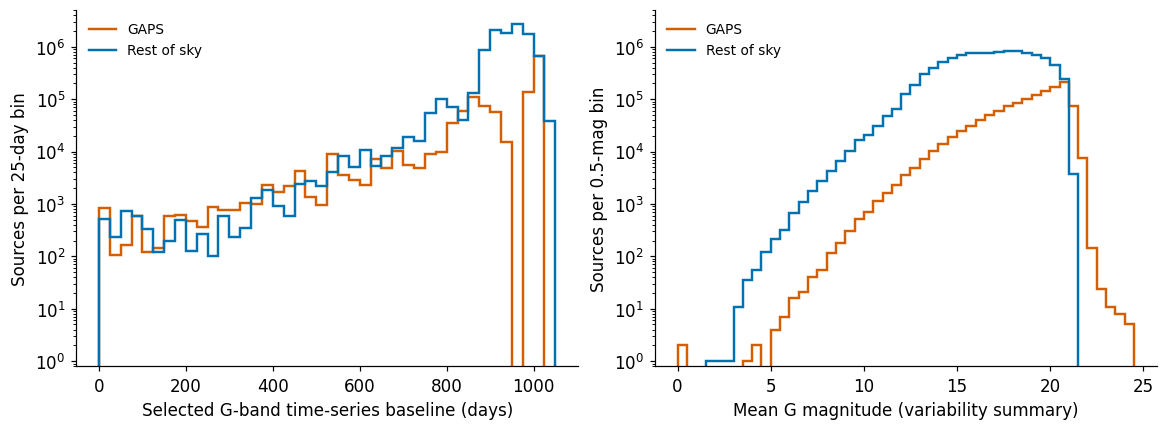

In [3]:
CHAR = DATA/'gaia_dr3_characterization'
populations = [('GAPS','#D55E00'),('Rest of sky','#0072B2')]
def split_histogram(name):
    frame = pd.read_csv(CHAR/f'{name}.csv')
    assert frame.n_sources.sum()==11754237
    frame['population'] = np.where(frame.in_andromeda_survey.astype(str).str.lower().eq('true'),'GAPS','Rest of sky')
    return frame

def weighted_quantile(frame,q=.5):
    a = frame.dropna(subset=['bin_value']).groupby('bin_value').n_sources.sum().sort_index()
    return a.index[np.searchsorted(np.cumsum(a),q*a.sum())]

fig,axes = plt.subplots(1,3,figsize=(12,3.6),sharey=True,layout='constrained')
count_rows = []
for ax,band in zip(axes,['g','bp','rp']):
    frame = split_histogram('epochs_'+band)
    for pop,color in populations:
        group = frame.loc[frame.population.eq(pop)]
        a = group.dropna(subset=['bin_value']).groupby('bin_value').n_sources.sum()
        # Identical integer bins, extended to cover all observed epoch counts.
        top = int(frame.bin_value.max())
        y = a.reindex(np.arange(top+1),fill_value=0).to_numpy()
        ax.stairs(y,np.arange(top+2)-.5,color=color,lw=1.5,label=f'{pop}; median {weighted_quantile(group):.0f}')
        count_rows.append(dict(band=band,population=pop,n_sources=int(group.n_sources.sum()),
            median_selected_epochs=float(weighted_quantile(group)),
            missing_summary=int(group.loc[group.bin_value.isna(),'n_sources'].sum()),
            zero_selected=int(group.loc[group.bin_value.eq(0),'n_sources'].sum())))
    ax.set(xlabel='Selected FoV epochs per source',title={'g':'G','bp':'BP','rp':'RP'}[band],yscale='log',ylim=(.8,1e6))
    ax.legend(fontsize=8,frameon=False)
axes[0].set_ylabel('Number of sources per integer count (log scale)')
fig.suptitle('Gaia DR3 epoch-photometry sample · sampling by passband',fontsize=13)
save_figure(fig,'gaia_dr3_epoch_count_histograms');plt.show()
count_summary = pd.DataFrame(count_rows)
count_summary.to_csv(TABLE/'gaia_dr3_epoch_count_summary.csv',index=False);display(count_summary)

fig,axes = plt.subplots(1,2,figsize=(10.5,3.8),layout='constrained')
for ax,name,width,xlabel in zip(axes,['baseline_g','magnitude_g'],[25,.5],
        ['Selected G-band time-series baseline (days)','Mean G magnitude (variability summary)']):
    frame = split_histogram(name)
    for pop,color in populations:
        group = frame.loc[frame.population.eq(pop)]
        a = group.dropna(subset=['bin_value']).groupby('bin_value').n_sources.sum().sort_index()
        bins = np.arange(int(a.index.min()),int(a.index.max())+1)
        ax.stairs(a.reindex(bins,fill_value=0),(np.append(bins,bins[-1]+1))*width,
                  color=color,lw=1.6,label=pop)
        print(f'{name}, {pop}: missing = {group.loc[group.bin_value.isna(),"n_sources"].sum():,}; total = {group.n_sources.sum():,}')
    ax.set(xlabel=xlabel,ylabel=f'Sources per {width:g}-'+('day' if name=='baseline_g' else 'mag')+' bin',yscale='log',ylim=(.8,5e6))
    ax.legend(frameon=False,fontsize=9)
save_figure(fig,'gaia_dr3_baseline_magnitude_histograms');plt.show()


### Native Gaia times, integration and the stored J1013 series

- Native Gaia DR3 photometric timestamps are barycentric Julian dates on the **TCB** scale, minus 2455197.5 days. The example below converts the **time scale** to TDB using Astropy; no extra observatory light-travel correction is applied.
- Approximately 4.42 s is the ungated integration per CCD. A G-band FoV value averages the available CCD measurements across an approximately 44 s passage. A 44 s uniform boxcar is a convenient approximation, not the exact CCD-weighted instrument response. Gates, missing CCDs and rejection alter individual observations; BP and RP are separate CCD measurements.
- The J1013 `gaia.dat` file has already been processed and lacks its original time-conversion record. Its historical BMJD-TDB interpretation is retained and explicitly **not verified**. The conversion function below is for native archive times and is not applied to J1013. A second conversion would be wrong if the source analysis already performed it. The nominal timing fits retain their documented response assumption.


In [4]:
def native_gaia_to_bmjd_tdb(time_offset_days):
    return Time(np.asarray(time_offset_days),2455197.5,format='jd',scale='tcb').tdb.mjd

native_demo = np.array([1700.,2200.,2700.])
converted_demo = native_gaia_to_bmjd_tdb(native_demo)
# Numerical coordinate difference between TCB and TDB, not a physical time interval.
scale_difference_s = (converted_demo-(native_demo+55197.0))*86400
assert np.all(scale_difference_s < 0)
display(pd.DataFrame({'native_BJD_TCB_minus_2455197p5':native_demo,
    'BMJD_TDB':converted_demo,'TDB_minus_TCB_coordinate_s':scale_difference_s}))


,native_BJD_TCB_minus_2455197p5,BMJD_TDB,TDB_minus_TCB_coordinate_s
0,1700.0,56896.999787,-18.424259
1,2200.0,57396.999779,-19.094083
2,2700.0,57896.999771,-19.763908


## What do different Gaia variables look like?

These panels use **Gaia DR3 archive downloads**, retained unchanged in `data/examples/`, and regenerated by the code below. They illustrate morphologies rather than reproduce each cited paper's full inference.

- **RR Lyrae:** rapid rise and slower decline, repeating on a fraction of a day. **Cepheid:** a larger, coherent pulsation over several days. G, BP and RP are shown at their own magnitudes; phase uses the catalogue fundamental periods and maximum-light epochs, on the native TCB scale ([RR Lyrae processing](https://doi.org/10.1051/0004-6361/202243964); [Cepheid processing](https://doi.org/10.1051/0004-6361/202243990)).
- **Young-source candidate in GAPS:** an actual GAPS member classified as YSO by Gaia (classification score 0.691). This is a candidate with no independent confirmation supplied here, not an established M31 young star. Its time-series view shows variability without imposing a period. GAPS can provide a variability-unselected comparison sample for such studies ([Mas et al. 2026](https://doi.org/10.1051/0004-6361/202554522)).
- **Short-period white dwarfs:** J1952+2509 is a known DAV pulsator and J0317−8532 a known spotted/magnetic rotator in [Steen et al. (2024)](https://doi.org/10.3847/1538-4357/ad3e60). Their published periods seed a narrow, explicitly local Gaia frequency refinement below; this is not an independent blind discovery. The flux errors are important, especially for the low-amplitude pulsator.
- **Planetary transit:** Gaia-2b is folded using the published circular-orbit ephemeris ([Panahi et al. 2022](https://doi.org/10.1051/0004-6361/202243497), Table 4). Its BJD epoch is treated as TDB for the Gaia/TESS comparison. Only the transit neighbourhood is shown, and no new planetary fit is made.

For each band we require finite times/fluxes, positive flux and errors, a false band-specific variability rejection flag, and a false `rejected_by_photometry` flag. We apply no brightness clipping. Native times are converted to TDB for the white-dwarf and planet folds. Raw downloads preserve rejected points and source/transit IDs. Source selections and ephemerides are recorded in `data/examples/manifest.json`; these examples do not alter the J1013 timing analysis.


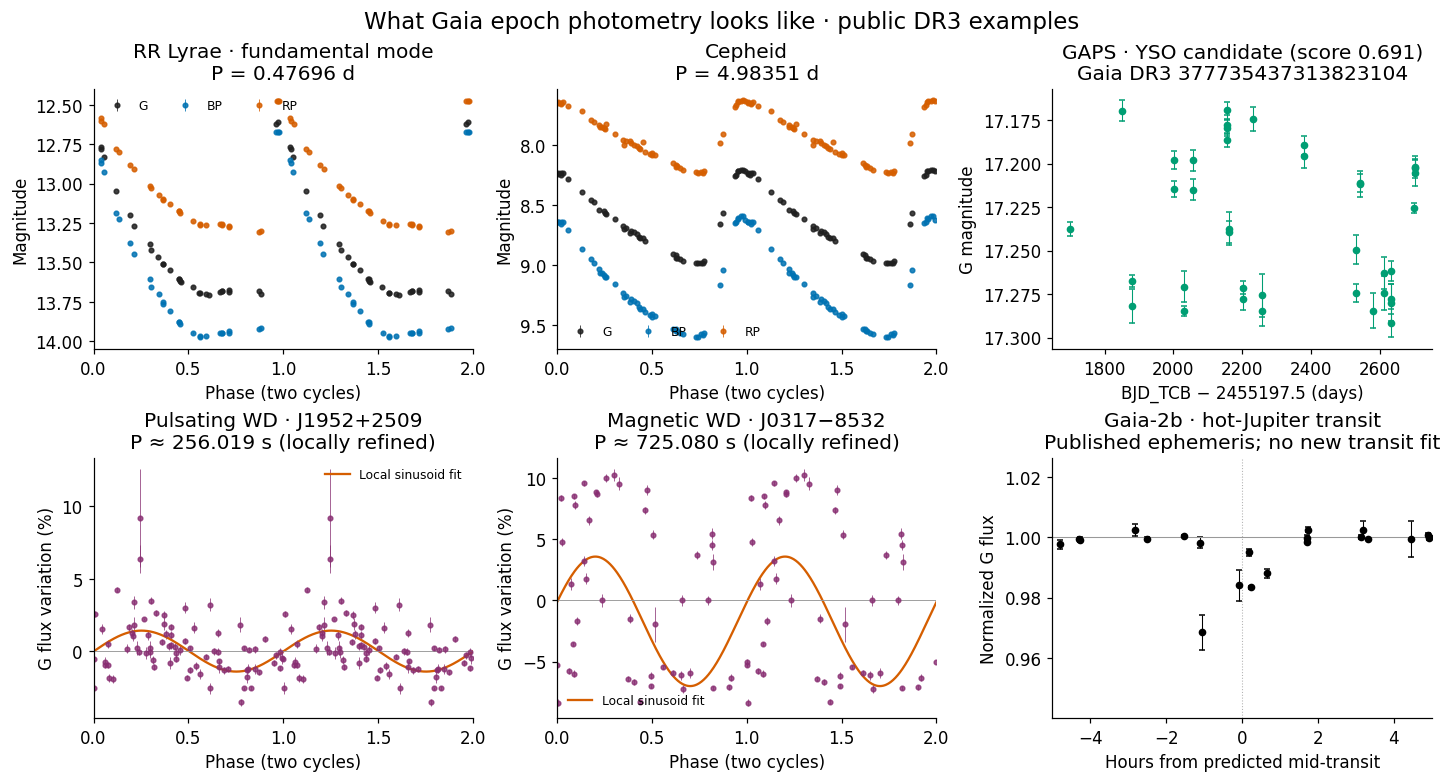

,key,source_id,band,n_selected,period_days,period_method
0,rrlyrae,3470927899858715008,g,30,0.476963,Gaia SOS catalogue; TCB
1,rrlyrae,3470927899858715008,bp,30,0.476963,Gaia SOS catalogue; TCB
2,rrlyrae,3470927899858715008,rp,30,0.476963,Gaia SOS catalogue; TCB
3,cepheid,2003938801532007808,g,45,4.983511,Gaia SOS catalogue; TCB
4,cepheid,2003938801532007808,bp,51,4.983511,Gaia SOS catalogue; TCB
5,cepheid,2003938801532007808,rp,51,4.983511,Gaia SOS catalogue; TCB
6,young,377735437313823104,g,38,NaN,No periodic model
7,wd_pulsator,2026653131220381824,g,79,0.002963,Local weighted sinusoid search ±0.05 s about S...
8,wd_rotation,4613612951211823104,g,46,0.008392,Local weighted sinusoid search ±0.05 s about S...
9,planet,1107980654748582144,g,131,3.691522,Panahi et al. circular ephemeris; BJD interpre...


In [5]:
from astropy.timeseries import LombScargle

example_manifest = json.loads((DATA/'examples/manifest.json').read_text())
examples = {item['key']:item for item in example_manifest['examples']}
BAND_COLOURS = {'g':'#202020','bp':'#0072B2','rp':'#D55E00'}

def example_band(item,band='g'):
    frame = pd.read_csv(ROOT/item['file'],dtype={'source_id':str,'transit_id':str})
    time_col = 'g_transit_time' if band=='g' else f'{band}_obs_time'
    prefix = 'g_transit' if band=='g' else band
    cols = [time_col,f'{prefix}_flux',f'{prefix}_flux_error',f'{prefix}_mag']
    valid = np.isfinite(frame[cols]).all(axis=1)
    valid &= (frame[f'{prefix}_flux']>0)&(frame[f'{prefix}_flux_error']>0)
    valid &= frame[f'variability_flag_{band}_reject'].eq(False)&frame.rejected_by_photometry.eq(False)
    out = frame.loc[valid].copy()
    return out[time_col].to_numpy(),out[f'{prefix}_flux'].to_numpy(),out[f'{prefix}_flux_error'].to_numpy(),out[f'{prefix}_mag'].to_numpy()

fig,axes = plt.subplots(2,3,figsize=(13,7),layout='constrained')
example_summary = []
for ax,key in zip(axes[0,:2],['rrlyrae','cepheid']):
    item = examples[key]
    for band in ['g','bp','rp']:
        t,f,e,m = example_band(item,band)
        phase = ((t-item['epoch_offset_days'])/item['period_days'])%1
        dm = 2.5/np.log(10)*e/f
        ax.errorbar(np.r_[phase,phase+1],np.tile(m,2),np.tile(dm,2),fmt='o',ms=3,
                    color=BAND_COLOURS[band],alpha=.85,elinewidth=.6,label=band.upper())
        example_summary.append(dict(key=key,source_id=item['source_id'],band=band,n_selected=len(t),period_days=item['period_days'],period_method='Gaia SOS catalogue; TCB'))
    ax.invert_yaxis();ax.set(xlabel='Phase (two cycles)',ylabel='Magnitude',
        title=f'{item["label"]}\nP = {item["period_days"]:.5f} d',xlim=(0,2))
    ax.legend(fontsize=8,frameon=False,ncol=3)

item = examples['young'];ax = axes[0,2]
t,f,e,m = example_band(item)
ax.errorbar(t,m,2.5/np.log(10)*e/f,fmt='o',color='#009E73',ms=4,capsize=2,elinewidth=.7)
ax.invert_yaxis();ax.set(xlabel='BJD_TCB − 2455197.5 (days)',ylabel='G magnitude',
    title='GAPS · YSO candidate (score 0.691)\nGaia DR3 '+item['source_id'])
example_summary.append(dict(key='young',source_id=item['source_id'],band='g',n_selected=len(t),period_days=np.nan,period_method='No periodic model'))

for ax,key in zip(axes[1,:2],['wd_pulsator','wd_rotation']):
    item = examples[key];native,f,e,m = example_band(item)
    t = native_gaia_to_bmjd_tdb(native);t = t-t.min()
    y = f/np.median(f)-1;error = e/np.median(f)
    seed = item['period_seed_seconds']
    # Narrow refinement around the rounded literature period: ±0.05 seconds.
    fmin = 86400/(seed+.05);fmax = 86400/(seed-.05)
    freq = np.linspace(fmin,fmax,max(1001,int((fmax-fmin)*np.ptp(t)*20)+1))
    ls = LombScargle(t,y,error)
    powers = ls.power(freq,method='cython');best = int(np.argmax(powers))
    assert 0<best<len(freq)-1,'Local refinement reached its boundary; inspect the seed.'
    frequency = freq[best];period_s = 86400/frequency
    phase = (t*frequency)%1
    ax.errorbar(np.r_[phase,phase+1],np.tile(y*100,2),np.tile(error*100,2),fmt='o',ms=3,
                 color='#882E72',alpha=.8,elinewidth=.6)
    pp = np.linspace(0,2,500)
    ax.plot(pp,100*ls.model(pp/frequency,frequency),color='#D55E00',lw=1.5,label='Local sinusoid fit')
    ax.axhline(0,lw=.6,color='.6')
    ax.set(xlabel='Phase (two cycles)',ylabel='G flux variation (%)',xlim=(0,2),
           title=f'{item["label"]}\nP ≈ {period_s:.3f} s (locally refined)')
    ax.legend(fontsize=8,frameon=False)
    example_summary.append(dict(key=key,source_id=item['source_id'],band='g',n_selected=len(t),period_days=period_s/86400,period_method='Local weighted sinusoid search ±0.05 s about Steen et al. period; TDB'))

item = examples['planet'];ax = axes[1,2]
native,f,e,m = example_band(item)
tdb_offset = native_gaia_to_bmjd_tdb(native)-55197.0
phase = ((tdb_offset-item['epoch_offset_days'])/item['period_days']+.5)%1-.5
hours = phase*item['period_days']*24
normal = np.median(f[np.abs(hours)>4])
ax.errorbar(hours,f/normal,e/normal,fmt='o',ms=4,color='k',capsize=2,elinewidth=.7)
ax.axhline(1,lw=.7,color='.6');ax.axvline(0,lw=.7,color='.7',ls=':')
ax.set(xlabel='Hours from predicted mid-transit',ylabel='Normalized G flux',xlim=(-5,5),
       title='Gaia-2b · hot-Jupiter transit\nPublished ephemeris; no new transit fit')
example_summary.append(dict(key='planet',source_id=item['source_id'],band='g',n_selected=len(native),period_days=item['period_days'],period_method='Panahi et al. circular ephemeris; BJD interpreted as TDB'))
fig.suptitle('What Gaia epoch photometry looks like · public DR3 examples',fontsize=15)
save_figure(fig,'gaia_dr3_science_light_curve_gallery');plt.show()
example_summary = pd.DataFrame(example_summary)
example_summary.to_csv(TABLE/'gaia_example_light_curve_summary.csv',index=False)
display(example_summary)


## 1. Gaia epoch photometry

`gaia.dat` contains 54 processed Gaia G-band measurements (release unconfirmed) for source
**5414242958825679488**. Columns 0, 2, and 3 supply time, flux, and flux error.

The file lacks the original archive metadata, quality flags, and time-conversion record.
Times are used unchanged, with the original analysis's BMJD-TDB interpretation assumed.
That scale requires verification before interpreting absolute timing offsets. The second
column is a constant 0.0001 day (8.64 s); its meaning is undocumented and it is not used as an exposure time.


54 points; 1009.98-day baseline


,time_as_stored_days,column_1_undocumented,flux,flux_error,column_4_undocumented,column_5_undocumented
0,56876.258842,0.0001,285.369581,6.60243,1.0,1.0
1,56875.684530,0.0001,284.032582,6.41852,1.0,1.0
2,57021.535103,0.0001,359.464336,4.84959,1.0,1.0
3,57130.762592,0.0001,266.909311,4.74919,1.0,1.0
4,56876.759148,0.0001,264.432916,4.73226,1.0,1.0


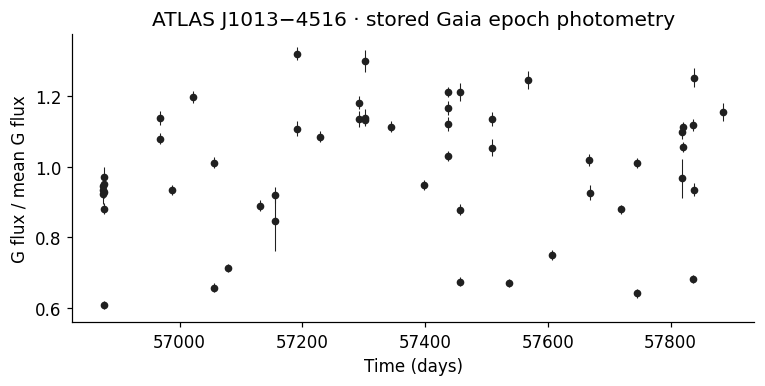

In [6]:
raw = np.loadtxt(DATA/'gaia.dat')
gaia = pd.DataFrame(raw, columns=['time_as_stored_days','column_1_undocumented',
                    'flux','flux_error','column_4_undocumented','column_5_undocumented'])
assert len(gaia) == 54
assert np.isfinite(gaia[['time_as_stored_days','flux','flux_error']]).all().all()
assert (gaia.flux_error > 0).all()
gaia.to_csv(TABLE/'gaia_epoch_photometry.csv',index=False)
print(f'{len(gaia)} points; {np.ptp(gaia.time_as_stored_days):.2f}-day baseline')
display(gaia.head())
fig, ax = plt.subplots(figsize=(8,3.4))
mean_flux = gaia.flux.mean()
ax.errorbar(gaia.time_as_stored_days,gaia.flux/mean_flux,
            gaia.flux_error/mean_flux,fmt='o',ms=4,color=COLORS['Gaia'],elinewidth=.7)
ax.set(xlabel='Time (days)',
       ylabel='G flux / mean G flux',title='ATLAS J1013−4516 · stored Gaia epoch photometry')
save_figure(fig,'j1013_gaia_epochs')
plt.show()


### Sampling and reported errors for the stored J1013 points

All 54 stored points are shown. Gaps use adjacent sorted timestamps; these are not CCD cadences. Relative flux errors are statistical uncertainties, not eclipse-timing uncertainties. The nearly simultaneous pair remains visible in the gap distribution.

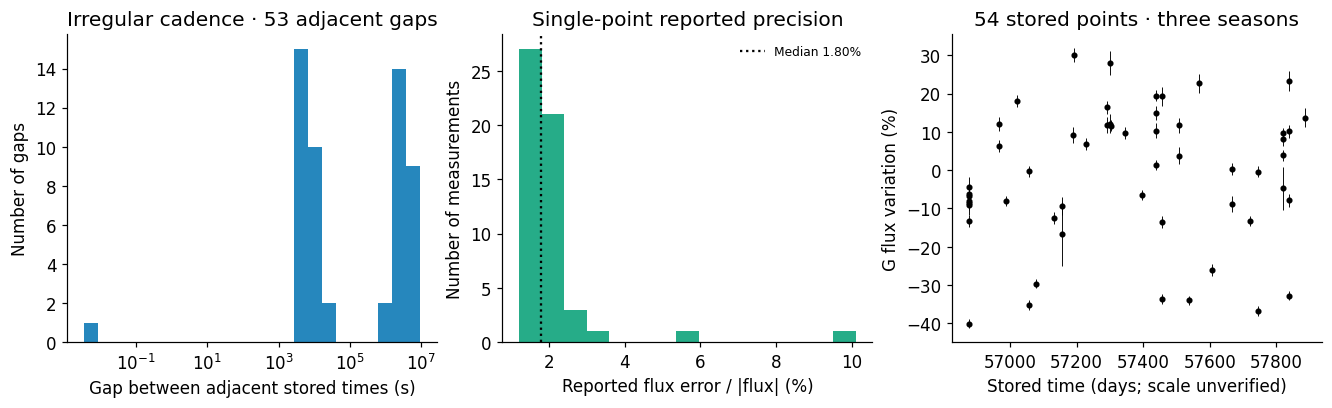

Smallest stored gap: 0.004320 s. It is not evidence of Gaia CCD cadence.


In [7]:
sorted_times = np.sort(gaia.time_as_stored_days.to_numpy())
gaps_s = np.diff(sorted_times)*86400
fractional_error = gaia.flux_error.to_numpy()/np.abs(gaia.flux.to_numpy())
fig,axes = plt.subplots(1,3,figsize=(12,3.6),layout='constrained')
axes[0].hist(gaps_s,bins=np.geomspace(gaps_s.min()*.8,gaps_s.max()*1.2,25),color='#0072B2',alpha=.85)
axes[0].set(xscale='log',xlabel='Gap between adjacent stored times (s)',ylabel='Number of gaps',title='Irregular cadence · 53 adjacent gaps')
axes[1].hist(100*fractional_error,bins=15,color='#009E73',alpha=.85)
axes[1].axvline(100*np.median(fractional_error),color='k',ls=':',label=f'Median {100*np.median(fractional_error):.2f}%')
axes[1].set(xlabel='Reported flux error / |flux| (%)',ylabel='Number of measurements',title='Single-point reported precision');axes[1].legend(fontsize=8,frameon=False)
axes[2].errorbar(gaia.time_as_stored_days,100*(gaia.flux/gaia.flux.median()-1),
                 100*gaia.flux_error/gaia.flux.median(),fmt='o',ms=3,color='k',elinewidth=.6)
axes[2].set(xlabel='Stored time (days; scale unverified)',ylabel='G flux variation (%)',title='54 stored points · three seasons')
save_figure(fig,'j1013_gaia_sampling_uncertainties');plt.show()
print(f'Smallest stored gap: {gaps_s.min():.6f} s. It is not evidence of Gaia CCD cadence.')


## 2. ATLAS photometry

The original ATLAS input is included as `atlas_reduced_original.txt`. Following the source
analysis, we select `chi/N < 10` and `mag5sig > 17`, match the c-band median to the o-band median,
and apply a pooled ±3-IQR flux cut. The fluxes are difference fluxes.

MJD UTC is converted to BMJD TDB using the source analysis's Palomar location and the coordinates
in `gaia_dr3.json`. This applies one site to all rows; a per-observatory time audit remains outstanding.


In [8]:
cols = ['MJD','m','dm','uJy','duJy','F','err','chiN','RA','Dec','x','y',
        'maj','min','phi','apfit','mag5sig','Sky','Obs']
atlas_raw = pd.read_csv(DATA/'atlas_reduced_original.txt',sep=r'\s+',comment='#',
                        names=cols,dtype={'F':str,'Obs':str})
atlas = atlas_raw.loc[(atlas_raw.chiN < 10) & (atlas_raw.mag5sig > 17)].copy()
n_quality = len(atlas)
delta_median = np.median(atlas.loc[atlas.F=='o','uJy']) - np.median(atlas.loc[atlas.F=='c','uJy'])
atlas.loc[atlas.F=='c','uJy'] += delta_median
iqr = np.diff(np.percentile(atlas.uJy,[25,75]))[0]
med = np.median(atlas.uJy)
atlas = atlas.loc[(atlas.uJy > med-3*iqr) & (atlas.uJy < med+3*iqr)].copy()
assert np.isfinite(atlas[['MJD','uJy','duJy']]).all().all() and (atlas.duJy > 0).all()
catalog = json.loads((DATA/'gaia_dr3.json').read_text())
coord = SkyCoord(catalog['coordinates']['ra_icrs_deg']*u.deg,
                 catalog['coordinates']['dec_icrs_deg']*u.deg)
palomar = EarthLocation.from_geocentric(-2410346.78217658*u.m,
                                       -4758666.82504051*u.m,3487942.97502457*u.m)
t = Time(atlas.MJD.to_numpy(),format='mjd',scale='utc')
atlas['bmjd_tdb'] = (t.tdb + t.tdb.light_travel_time(coord,kind='barycentric',location=palomar)).mjd
atlas.to_csv(TABLE/'atlas_cleaned_photometry.csv',index=False)
print(f'ATLAS: {len(atlas_raw)} input → {n_quality} quality-selected → {len(atlas)} IQR-selected')
display(atlas.groupby('F').agg(n=('uJy','size'),first_mjd=('MJD','min'),last_mjd=('MJD','max')))


ATLAS: 2128 input → 2007 quality-selected → 1946 IQR-selected


,n,first_mjd,last_mjd
F,,,
c,449,57453.407532,60648.321291
g,8,58195.330590,58195.424552
o,1489,57404.516962,60654.049231


## 3. Gaia/ATLAS phase-folded light curves

We use the published quadratic ephemeris and inverse-variance averages in 50 phase bins.
Gaia flux is normalized by its mean. Each ATLAS band's folded flux is shifted and scaled to
match Gaia's folded interquartile range, following the original comparison figure.

The overlay compares waveform shapes rather than absolute amplitudes or colors. The three
displayed cycles repeat the same measurements. This fold uses the published ephemeris; it does
not independently estimate a period or period derivative.


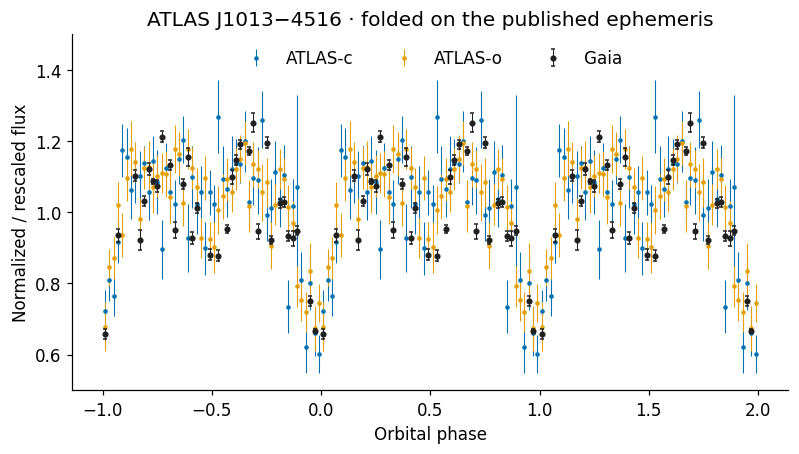

In [9]:
def phase_fold(time, period_days, pdot, t0):
    dt = np.asarray(time)-t0
    return ((dt - .5*pdot/period_days*dt**2) % period_days)/period_days

def binned_fold(time, flux, error):
    phase = phase_fold(time,P_PUBLISHED_S/86400,PDOT_PUBLISHED,T0_PUBLISHED)
    edges = np.linspace(0,1,N_PHASE_BINS+1)
    result = []
    for lo,hi in zip(edges[:-1],edges[1:]):
        m = (phase >= lo) & (phase < hi)
        if m.any():
            w = 1/np.asarray(error)[m]**2
            result.append([(lo+hi)/2,np.sum(np.asarray(flux)[m]*w)/w.sum(),np.sqrt(1/w.sum())])
        else:
            result.append([(lo+hi)/2,np.nan,np.nan])
    return np.asarray(result)

def repeated_cycles(binned):
    return np.vstack([binned+[-1,0,0],binned,binned+[1,0,0]])

g = binned_fold(gaia.time_as_stored_days,gaia.flux/mean_flux,gaia.flux_error/mean_flux)
# Quantiles of the repeated arrays reproduce the original notebook exactly.
qg = np.nanpercentile(repeated_cycles(g)[:,1],[25,75])
folds = {'Gaia':g}
transforms = []
for band in ('c','o'):
    d = atlas.loc[atlas.F==band]
    y,dy = d.uJy.to_numpy(),d.duJy.to_numpy()
    if band == 'o':
        dy = dy/y.mean(); y = y/y.mean()
    binned = binned_fold(d.bmjd_tdb,y,dy)
    q = np.percentile(repeated_cycles(binned)[:,1],[25,75])
    scale = np.diff(qg)[0]/np.diff(q)[0]
    offset = qg[0]-scale*q[0]
    binned[:,1] = scale*binned[:,1]+offset
    binned[:,2] *= scale
    folds[f'ATLAS-{band}'] = binned
    transforms.append(dict(band=band,scale=scale,offset=offset))
pd.DataFrame(transforms).to_csv(TABLE/'atlas_display_transforms.csv',index=False)
all_folds = pd.concat([pd.DataFrame(a,columns=['phase','display_flux','display_flux_error']).assign(survey=label)
                       for label,a in folds.items()],ignore_index=True)
all_folds.to_csv(TABLE/'gaia_atlas_folded_50bins.csv',index=False)

fig, ax = plt.subplots(figsize=(8.4,4.2))
for label in ('ATLAS-c','ATLAS-o','Gaia'):
    b = repeated_cycles(folds[label])
    ax.errorbar(b[:,0],b[:,1],b[:,2],fmt='o' if label=='Gaia' else '.',
                ms=3 if label=='Gaia' else 4,elinewidth=.7,capsize=1 if label=='Gaia' else 0,
                color=COLORS[label],label=label,zorder=3 if label=='Gaia' else 2)
ax.set(xlabel='Orbital phase',ylabel='Normalized / rescaled flux',ylim=(.5,1.5),
       title='ATLAS J1013−4516 · folded on the published ephemeris')
ax.legend(ncol=3,loc='upper center',frameon=False)
save_figure(fig,'j1013_gaia_atlas_fold')
plt.show()


## 4. Non-Gaia timing epochs

`other_timing_epochs.csv` contains 12 epochs: seven ULTRACAM, three ATLAS and two
Proto-Lightspeed timings. Instrument assignments follow the original figure annotations.
The stored time scale is assumed to be BMJD TDB. The uncertainty used is `sigma_s`;
the day-unit version was rounded. Integer cycles are reconstructed from the stored reference
period. Previously supplied Gaia timing rows are excluded from the input files and analysis.


In [10]:
epochs = pd.read_csv(DATA/'other_timing_epochs.csv')
assert len(epochs)==12 and not (epochs.instrument=='Gaia').any()
np.testing.assert_allclose(epochs.sigma_s,epochs.sigma_days*86400,atol=0.005)
T_REF = float(epochs.iloc[0].time_as_stored_days)
P_REF_D = float(epochs.iloc[0].reference_period_days)
P_REF_S = P_REF_D*86400
epochs['cycle_integer'] = np.rint(epochs.dt_days/P_REF_D).astype('int64')
np.testing.assert_allclose((epochs.dt_days-epochs.cycle_integer*P_REF_D)*86400,epochs.oc_s,atol=1e-5)
epochs['year_for_display'] = Time(epochs.time_as_stored_days.to_numpy(),format='mjd',scale='tdb').decimalyear
print(f'Common linear reference: T_ref = {T_REF:.10f}, P_ref = {P_REF_S:.12f} s')
display(epochs[['instrument','time_as_stored_days','cycle_integer','oc_s','sigma_s']].sort_values('time_as_stored_days'))


Common linear reference: T_ref = 60033.2044883359, P_ref = 513.593300316548 s


,instrument,time_as_stored_days,cycle_integer,oc_s,sigma_s
7,ATLAS,58300.325977,-291516,-38.877951,8.531964
8,ATLAS,59100.010048,-156988,-14.646860,5.193422
9,ATLAS,59657.217320,-63251,-1.495497,3.861625
0,ULTRACAM,60033.204488,0,0.000000,0.434442
1,ULTRACAM,60034.262585,178,-0.050503,0.691042
2,ULTRACAM,60347.382093,52853,-1.626978,1.264423
3,ULTRACAM,60348.214297,52993,-2.252206,1.650222
4,ULTRACAM,60675.279283,108014,-4.497383,0.756526
5,ULTRACAM,60727.268718,116760,-4.315182,0.742279
6,ULTRACAM,60763.172679,122800,-5.587977,0.777115


## 5. A common timing fit for the before/after comparison

For both sets we fit $O-C=a+b(E/10^5)+c(E/10^5)^2$ by weighted least squares,
where $E$ is integer cycle count on the same linear reference ephemeris.
The local period is $P=P_{\rm ref}+b/10^5$ and $\dot P=2(c/10^{10})/P$.
We propagate the full coefficient covariance to $\dot P$. Formal errors use the supplied
non-Gaia timing errors and the residual-scaled Gaia profile errors below; the joint fit
applies no additional reduced-$\chi^2$ rescaling. The final panels share axes and reference.


In [11]:
def timing_design(cycles):
    x = np.asarray(cycles)/1e5
    return np.column_stack([np.ones_like(x),x,x*x])

def fit_timing(frame):
    X = timing_design(frame.cycle_integer.to_numpy())
    sigma = frame.sigma_s.to_numpy()
    Xw = X/sigma[:,None]
    beta = np.linalg.lstsq(Xw,frame.oc_s.to_numpy()/sigma,rcond=None)[0]
    covariance = np.linalg.inv(Xw.T@Xw)
    period = P_REF_S+beta[1]/1e5
    pdot = 2*beta[2]/1e10/period
    gradient = np.array([0.,-pdot/(period*1e5),2/(1e10*period)])
    uncertainty = np.sqrt(gradient@covariance@gradient)
    residual = frame.oc_s.to_numpy()-X@beta
    return dict(beta=beta,covariance=covariance,pdot=pdot,sigma=uncertainty,
                chi2=float(np.sum((residual/sigma)**2)),dof=len(frame)-3,n=len(frame))

before = fit_timing(epochs)
print(f'Before Gaia: Pdot = ({before["pdot"]/1e-12:.3f} ± {before["sigma"]/1e-12:.3f}) × 10^-12 s/s')


Before Gaia: Pdot = (-1.728 ± 0.168) × 10^-12 s/s


## 6. Measure seasonal Gaia epochs from photometry

We fit the saved high-speed g-band LCURVE waveform to each Gaia season with a free time shift,
positive amplitude, and flux offset. The model geometry is fixed; its saved conjunction phase
sets the template zero point. We use explicit boundaries at 57200 and 57600 days, yielding
20, 19, and 15 measurements. The original analysis's three-season selection is unknown.

Within-season phase evolution comes from a quadratic ephemeris fitted to the **12 non-Gaia
timings only**, while each Gaia seasonal shift remains free. The published Pdot is not imposed.
Uncertainty in this external phase evolution is not propagated, so the timing errors are conditional.

Each reported epoch is the integer cycle nearest the inverse-variance-weighted mean observing
cycle of its season. No supplied Gaia timings are used, including for reporting-cycle selection.
Times remain on the stored scale. Two measurements are about 4 ms apart; their independence
cannot be checked without transit IDs, and both are retained.


In [12]:
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar, brentq

# Fit only the non-Gaia timing rows for phase evolution within each season.
external = pd.read_csv(DATA/'other_timing_epochs.csv')
E_ext = np.rint(external.dt_days.to_numpy()*86400/P_REF_S).astype('int64')
X_ext = np.column_stack([np.ones(len(E_ext)),E_ext/1e5,(E_ext/1e5)**2])
w_ext = 1/external.sigma_s.to_numpy()
b_ext = np.linalg.lstsq(X_ext*w_ext[:,None],external.oc_s.to_numpy()*w_ext,rcond=None)[0]
EXT_A = b_ext[0]
EXT_P = P_REF_S+b_ext[1]/1e5
EXT_C = b_ext[2]/1e10

def external_epoch(cycle):
    return T_REF+(EXT_A+EXT_P*np.asarray(cycle)+EXT_C*np.asarray(cycle)**2)/86400

def external_cycles(time):
    dt = (np.asarray(time)-T_REF)*86400-EXT_A
    # Stable inverse of dt = P E + C E^2.
    return 2*dt/(EXT_P+np.sqrt(EXT_P**2+4*EXT_C*dt))

model = np.loadtxt(DATA/'ultracam_g_lcurve_template.dat')
template_meta = json.loads((DATA/'template_metadata.json').read_text())
xp = model[:,0]-template_meta['phase_conjunction']
yp = model[:,2]/np.mean(model[:,2])
assert np.isclose(xp[0],0) and np.isclose(xp[-1],1)
assert np.isclose(yp[0],yp[-1],atol=1e-8)
yp[-1] = yp[0]  # exactly close the periodic spline (roundoff only)
timing_template = CubicSpline(xp,yp,bc_type='periodic')
print(f'Non-Gaia-only phase evolution: Pdot = {2*EXT_C/EXT_P/1e-12:.3f} × 10^-12 s/s')
print('Gaia seasonal shifts are fitted to the individual flux measurements.')


Non-Gaia-only phase evolution: Pdot = -1.728 × 10^-12 s/s
Gaia seasonal shifts are fitted to the individual flux measurements.


### Timing profiles and sensitivity checks

The nominal model averages the waveform over a **44-second uniform boxcar**. This is an assumed
response, because the effective response is undocumented in the input. We also fit with zero
additional averaging. At each trial shift, amplitude and offset are solved analytically; the
search covers one orbital cycle and refines the best minimum.

The error interval is the contiguous region around that minimum satisfying

$$\Delta\chi^2\leq\max[1,\chi^2_{\min}/(N-3)].$$

This scales the local profile errors by the residual scatter when the fit is poor. It does not
account for waveform-transfer errors, correlated measurements, the time scale, or uncertainty
in phase evolution. We also allow a first-harmonic sine/cosine baseline to test waveform and
eclipse-label sensitivity. The resulting epochs are exploratory.


In [13]:
def fit_gaia_season(t,y,error,exposure_s=44.0,harmonic=False):
    t,y,error = map(np.asarray,(t,y,error))
    base_phase = external_cycles(t) % 1
    nuisance = np.column_stack([np.ones(len(t)),np.cos(2*np.pi*base_phase),np.sin(2*np.pi*base_phase)]) if harmonic else np.ones((len(t),1))
    # Weighted projection removes nuisance coefficients at every trial shift.
    Q,_ = np.linalg.qr(nuisance/error[:,None],mode='reduced')
    yw = y/error
    yr = yw-Q@(Q.T@yw)
    offsets = ((np.arange(21)+.5)/21-.5)*exposure_s

    def template_at(shifts):
        shifts = np.atleast_1d(shifts)
        tt = t[None,:,None]+(offsets[None,None,:]-shifts[:,None,None])/86400
        return timing_template(external_cycles(tt)%1).mean(axis=2)

    def profile(shifts):
        m = template_at(shifts)/error[None,:]
        mr = m-(m@Q)@Q.T
        denom = np.sum(mr*mr,axis=1)
        amplitude = (mr@yr)/denom
        chi = yr@yr-(mr@yr)**2/denom
        return np.where(amplitude>0,np.maximum(chi,0),1e30)

    grid = np.linspace(-P_REF_S/2,P_REF_S/2,2049)
    chi = profile(grid)
    i = int(np.argmin(chi))
    opt = minimize_scalar(lambda sh:float(profile([sh])[0]),
            bounds=(grid[max(0,i-1)],grid[min(len(grid)-1,i+1)]),method='bounded',options={'xatol':1e-7})
    shift,cmin = float(opt.x),float(opt.fun)
    n_parameters = nuisance.shape[1]+2  # nuisance + template amplitude + shift
    dof = len(t)-n_parameters
    error_scale = max(1,cmin/dof)
    threshold = cmin+error_scale

    def crossing(direction):
        trial = shift+direction*np.linspace(0,P_REF_S/2,2049)
        v = profile(trial)-threshold
        hits = np.flatnonzero(v>0)
        if not len(hits): return np.nan
        j = int(hits[0])
        return brentq(lambda sh:float(profile([sh])[0]-threshold),*sorted([trial[j-1],trial[j]]),xtol=1e-7)
    lower,upper = crossing(-1),crossing(1)
    X = np.column_stack([template_at([shift])[0],nuisance])
    coeff = np.linalg.lstsq(X/error[:,None],yw,rcond=None)[0]
    circular_distance = np.abs((grid-shift+P_REF_S/2)%P_REF_S-P_REF_S/2)
    opposite = circular_distance > P_REF_S/4
    return dict(shift_s=shift,error_minus_s=shift-lower,error_plus_s=upper-shift,
                chi2=cmin,dof=dof,chi2nu=cmin/dof,error_scale=error_scale,
                opposite_half_delta_chi2=(float(chi[opposite].min()-cmin) if chi[opposite].min()<1e29 else np.nan),
                grid=grid,chi2_profile=chi,coeff=coeff,profile=profile,
                template_at=template_at,model=X@coeff)

# Sign/units sanity check at the actual cadence: an exact shifted template must be recovered.
test_t = gaia.time_as_stored_days.to_numpy()[:20]
test_offsets = ((np.arange(21)+.5)/21-.5)*44
injected_shift_s = 7.25
test_y = .15+1.2*timing_template(external_cycles(test_t[:,None]+(test_offsets-injected_shift_s)/86400)%1).mean(axis=1)
injected = fit_gaia_season(test_t,test_y,np.full(len(test_t),.02))
assert abs(injected['shift_s']-injected_shift_s)<0.005
print(f'Synthetic shift recovery: injected {injected_shift_s:.3f} s, recovered {injected["shift_s"]:.3f} s')


Synthetic shift recovery: injected 7.250 s, recovered 7.250 s


,season,n,time_as_stored_days,oc_s,error_minus_s,error_plus_s,chi2nu
0,1,20,56995.822002,-105.306066,11.805060,10.804857,34.269343
1,2,19,57410.655932,-75.877183,8.663374,7.658741,15.685821
2,3,15,57769.125023,-76.771403,8.162911,8.013673,19.720447


,season,variant,shift_s,delta_from_nominal_s,chi2nu,half_cycle_switch
0,1,44s fixed template,14.972866,0.000000,34.269343,False
1,1,0s extra smearing,18.282125,3.309260,33.953662,False
2,1,44s + first-harmonic baseline,-244.541868,254.078567,29.298732,True
3,2,44s fixed template,14.320772,0.000000,15.685821,False
4,2,0s extra smearing,14.230907,-0.089865,15.812283,False
5,2,44s + first-harmonic baseline,-242.296254,-256.617026,12.189320,True
6,3,44s fixed template,-9.085730,0.000000,19.720447,False
7,3,0s extra smearing,-10.002415,-0.916686,18.856396,False
8,3,44s + first-harmonic baseline,-6.924109,2.161621,20.147238,False


Profile errors are conditional; inspect χ² and the eclipse-label sensitivity before interpreting the epochs.


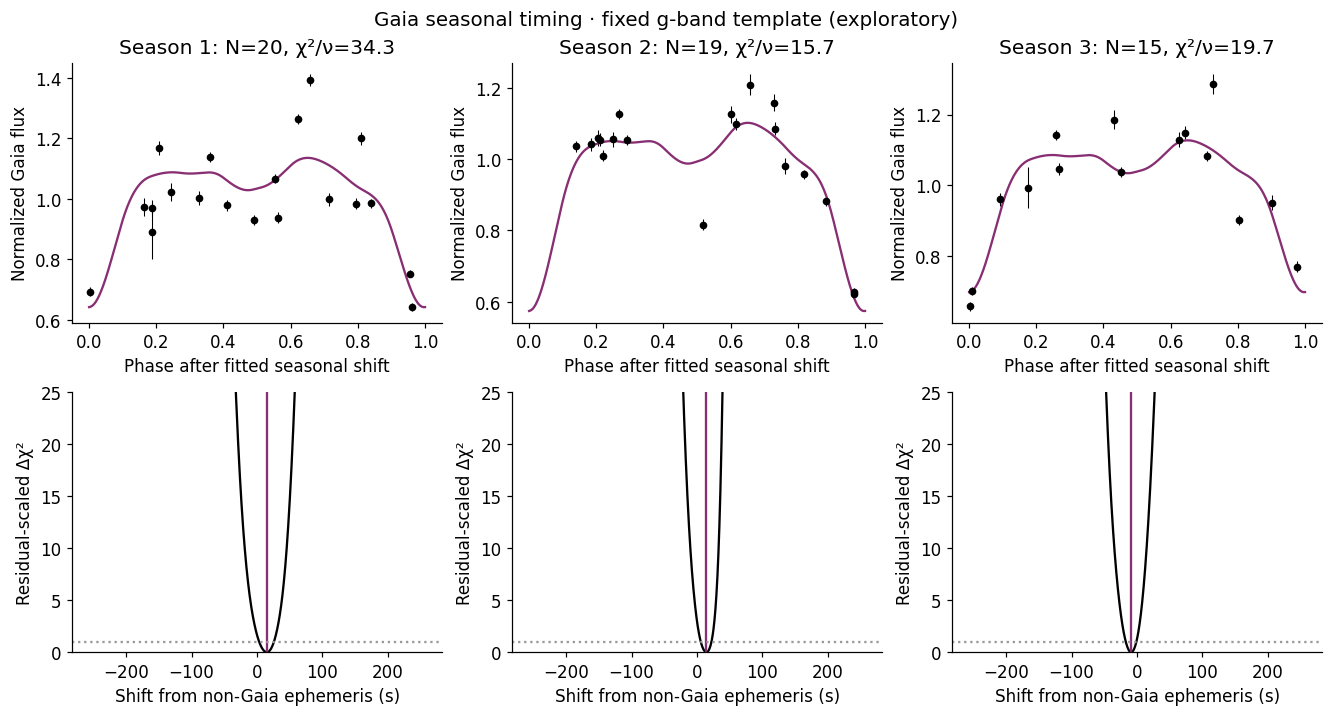

In [14]:
SEASON_EDGES = [-np.inf,57200,57600,np.inf]
measured_rows, sensitivity_rows, season_fits = [],[],[]
for j,(lo,hi) in enumerate(zip(SEASON_EDGES[:-1],SEASON_EDGES[1:])):
    d = gaia.loc[(gaia.time_as_stored_days>=lo)&(gaia.time_as_stored_days<hi)]
    t = d.time_as_stored_days.to_numpy()
    mean = d.flux.mean(); y = d.flux.to_numpy()/mean; error = d.flux_error.to_numpy()/mean
    result = fit_gaia_season(t,y,error)
    unsmeared = fit_gaia_season(t,y,error,exposure_s=0)
    flexible = fit_gaia_season(t,y,error,harmonic=True)
    # Report a conjunction near the weighted centre of the observed season.
    report_cycle = int(np.rint(np.average(external_cycles(t),weights=1/error**2)))
    measured_time = float(external_epoch(report_cycle)+result['shift_s']/86400)
    measured_oc = (measured_time-(T_REF+report_cycle*P_REF_D))*86400
    row = dict(season=j+1,n=len(t),first_time_as_stored_days=t.min(),last_time_as_stored_days=t.max(),
               cycle_integer=report_cycle,time_as_stored_days=measured_time,oc_s=measured_oc,
               sigma_s=max(result['error_minus_s'],result['error_plus_s']),
               error_minus_s=result['error_minus_s'],error_plus_s=result['error_plus_s'],
               shift_from_non_gaia_ephemeris_s=result['shift_s'],chi2nu=result['chi2nu'],
               opposite_half_delta_chi2=result['opposite_half_delta_chi2'],
               status='Exploratory fixed-template remeasurement; time scale assumed as stored')
    measured_rows.append(row)
    for label,fit in [('44s fixed template',result),('0s extra smearing',unsmeared),('44s + first-harmonic baseline',flexible)]:
        delta = (fit['shift_s']-result['shift_s']+P_REF_S/2)%P_REF_S-P_REF_S/2
        sensitivity_rows.append(dict(season=j+1,variant=label,shift_s=fit['shift_s'],
                 delta_from_nominal_s=delta,chi2nu=fit['chi2nu'],half_cycle_switch=abs(delta)>P_REF_S/4))
    season_fits.append(dict(data=d,t=t,y=y,error=error,result=result))

measured_gaia = pd.DataFrame(measured_rows)
timing_sensitivity = pd.DataFrame(sensitivity_rows)
measured_gaia.to_csv(TABLE/'gaia_measured_timing_epochs.csv',index=False)
timing_sensitivity.to_csv(TABLE/'gaia_timing_sensitivity.csv',index=False)
display(measured_gaia[['season','n','time_as_stored_days','oc_s','error_minus_s','error_plus_s','chi2nu']])
display(timing_sensitivity)
print('Profile errors are conditional; inspect χ² and the eclipse-label sensitivity before interpreting the epochs.')

fig,axes = plt.subplots(2,3,figsize=(12,6.4),layout='constrained')
for j,group in enumerate(season_fits):
    t,y,error,result = group['t'],group['y'],group['error'],group['result']
    ph = external_cycles(t-result['shift_s']/86400)%1
    ax = axes[0,j];ax.errorbar(ph,y,error,fmt='o',ms=4,color='k',elinewidth=.7)
    pp = np.linspace(0,1,600)
    smooth = timing_template((pp[:,None]+(((np.arange(21)+.5)/21-.5)*44/EXT_P))%1).mean(axis=1)
    ax.plot(pp,result['coeff'][0]*smooth+result['coeff'][1],color='#882E72')
    ax.set(xlabel='Phase after fitted seasonal shift',ylabel='Normalized Gaia flux',title=f'Season {j+1}: N={len(t)}, χ²/ν={result["chi2nu"]:.1f}')
    ax = axes[1,j]
    ax.plot(result['grid'],(result['chi2_profile']-result['chi2'])/result['error_scale'],color='k')
    ax.axvline(result['shift_s'],color='#882E72');ax.axhline(1,color='.6',ls=':')
    ax.set(xlabel='Shift from non-Gaia ephemeris (s)',ylabel='Residual-scaled Δχ²',ylim=(0,25))
fig.suptitle('Gaia seasonal timing · fixed g-band template (exploratory)',fontsize=13)
save_figure(fig,'j1013_gaia_timing_profiles')
plt.show()


## 7. Before and after adding the flux-derived Gaia timings

The left panel uses only the 12 non-Gaia epochs; the right adds the three epochs measured
above. Both fits use the same model, linear reference, axes and formal-covariance calculation.
For Gaia we use the larger asymmetric profile error. Shaded bands are pointwise 1σ model bands.

The uncertainty reduction is **conditional**, not a validated improvement in total accuracy.
Gaia timings depend on the non-Gaia within-season ephemeris, whose uncertainty and resulting
cross-correlations are not propagated. The g-to-G template transfer, assumed response,
possible half-cycle switches, unknown stored time scale and correlated points remain relevant.
The sensitivity table above shows why these measurements should remain exploratory.


,dataset,n_epochs,pdot_s_per_s,conditional_sigma_s_per_s,chi2,dof
0,Without Gaia,12,-1.728180e-12,1.677485e-13,3.960245,9
1,With flux-derived Gaia,15,-1.650306e-12,7.339677e-14,8.348711,12


Conditional formal uncertainty: 0.168 → 0.073 × 10^-12 s/s
2.29× smaller; 56.2% reduction. Not a total systematic-error budget.


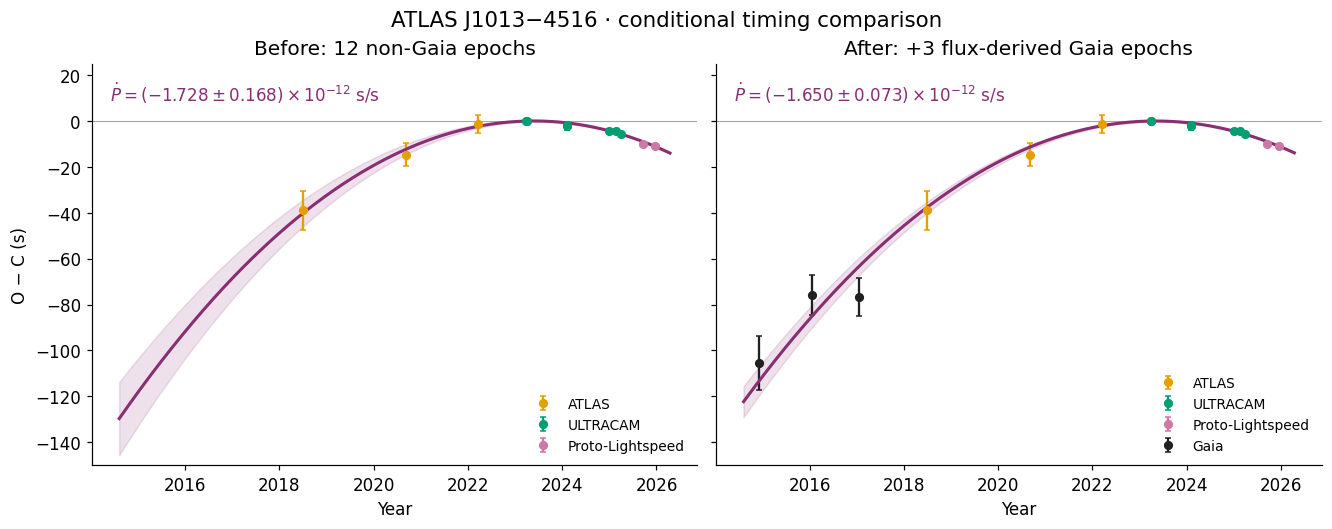

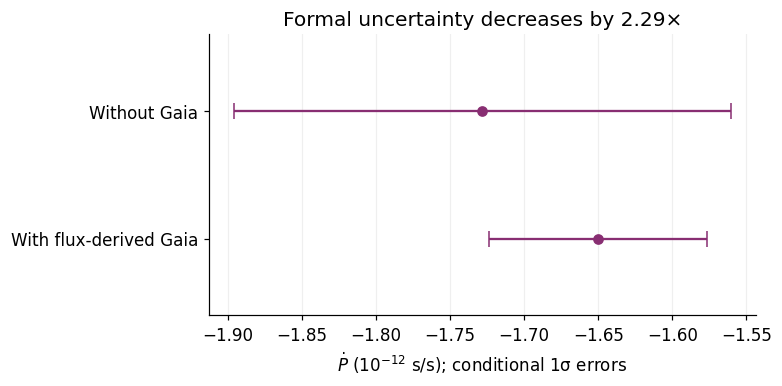

In [15]:
fresh = measured_gaia[['time_as_stored_days','sigma_s','cycle_integer','oc_s']].copy()
fresh['instrument'] = 'Gaia'
remeasured = pd.concat([epochs[['time_as_stored_days','sigma_s','cycle_integer','oc_s','instrument']],fresh],ignore_index=True)
remeasured['year_for_display'] = Time(remeasured.time_as_stored_days.to_numpy(),format='mjd',scale='tdb').decimalyear
after = fit_timing(remeasured)
comparison = pd.DataFrame([dict(dataset=label,n_epochs=fit['n'],pdot_s_per_s=fit['pdot'],
    conditional_sigma_s_per_s=fit['sigma'],chi2=fit['chi2'],dof=fit['dof'])
    for label,fit in [('Without Gaia',before),('With flux-derived Gaia',after)]])
comparison.to_csv(TABLE/'pdot_before_after_gaia.csv',index=False)
remeasured.sort_values('time_as_stored_days').to_csv(TABLE/'timing_epochs_remeasured_gaia.csv',index=False)
improvement = before['sigma']/after['sigma']
summary = dict(comparison=comparison.to_dict(orient='records'),formal_error_improvement_factor=improvement,
    status='Exploratory; formal errors conditional on timing and template assumptions',
    gaia_response_assumption_s=44,gaia_reporting_cycle='Inverse-variance-weighted observing-cycle centre',
    unresolved_systematics=['Stored Gaia time scale','g-to-G template transfer','half-cycle labeling',
                           'correlated measurements','external intra-season ephemeris uncertainty'])
(TABLE/'oc_remeasured_gaia_summary.json').write_text(json.dumps(summary,indent=2))
display(comparison)
print(f'Conditional formal uncertainty: {before["sigma"]/1e-12:.3f} → {after["sigma"]/1e-12:.3f} × 10^-12 s/s')
print(f'{improvement:.2f}× smaller; {100*(1-1/improvement):.1f}% reduction. Not a total systematic-error budget.')

cycle_grid = np.linspace(remeasured.cycle_integer.min()-20000,remeasured.cycle_integer.max()+20000,600)
Xg = timing_design(cycle_grid)
years = Time(T_REF+cycle_grid*P_REF_D,format='mjd',scale='tdb').decimalyear
fig,axes = plt.subplots(1,2,figsize=(12,4.7),sharex=True,sharey=True,layout='constrained')
for ax,frame,fit,title in zip(axes,[epochs,remeasured],[before,after],['Before: 12 non-Gaia epochs','After: +3 flux-derived Gaia epochs']):
    for instrument in ('ATLAS','ULTRACAM','Proto-Lightspeed','Gaia'):
        d = frame.loc[frame.instrument==instrument]
        if len(d):
            ax.errorbar(d.year_for_display,d.oc_s,d.sigma_s,fmt='o',ms=5,capsize=2,
                        color=COLORS[instrument],label=instrument)
    curve = Xg@fit['beta']
    band = np.sqrt(np.einsum('ij,jk,ik->i',Xg,fit['covariance'],Xg))
    ax.plot(years,curve,color='#882E72',lw=2)
    ax.fill_between(years,curve-band,curve+band,color='#882E72',alpha=.14)
    ax.axhline(0,color='.65',lw=.7,zorder=0)
    ax.set(xlabel='Year',title=title,ylim=(-150,25))
    ax.text(.03,.96,rf'$\dot P=({fit["pdot"]/1e-12:.3f}\pm{fit["sigma"]/1e-12:.3f})\times10^{{-12}}$ s/s',
            va='top',transform=ax.transAxes,fontsize=11,color='#882E72')
    ax.legend(loc='lower right',fontsize=9,frameon=False)
axes[0].set_ylabel('O − C (s)')
fig.suptitle('ATLAS J1013−4516 · conditional timing comparison',fontsize=14)
save_figure(fig,'j1013_oc_before_after_gaia')
plt.show()

fig,ax = plt.subplots(figsize=(7,3.4),layout='constrained')
labels = ['Without Gaia','With flux-derived Gaia']
values = comparison.pdot_s_per_s.to_numpy()/1e-12
errors = comparison.conditional_sigma_s_per_s.to_numpy()/1e-12
ax.errorbar(values,[1,0],xerr=errors,fmt='o',color='#882E72',capsize=5)
ax.set(yticks=[1,0],yticklabels=labels,ylim=(-.6,1.6),
       xlabel=r'$\dot P$ ($10^{-12}$ s/s); conditional 1σ errors',
       title=f'Formal uncertainty decreases by {improvement:.2f}×')
ax.grid(axis='x',alpha=.2)
save_figure(fig,'j1013_pdot_before_after_gaia')
plt.show()


## Data provenance and outputs

Inputs are author-provided analysis products for ATLAS J1013−4516. Original analysis-relative
filenames and SHA256 checksums are in `data/source_manifest.json`. The non-Gaia timing CSV
retains source-row identifiers for traceability; supplied Gaia timing rows are not bundled.

The folded comparison follows `scripts/gaia/plot_gaia_atlas.ipynb` and `utils/photometry.py`
in the source analysis. The template is `results/lcurve/good/good_model_g.dat`, with phase
origin from `good.mod`. The original Gaia archive response and ingestion documentation have
not been located; `gaia.dat` is a processed analysis product, with release unconfirmed.
The seasonal timing estimator and assumptions are specified in section 6.

PDF/PNG figures are written to `figures/`. `tables/pdot_before_after_gaia.csv` contains the
two fits, `gaia_measured_timing_epochs.csv` the new seasonal timings, and
`gaia_timing_sensitivity.csv` the waveform checks. The joint timing table contains only
non-Gaia inputs and the newly measured Gaia epochs.
